# Strahlungsbeitrag zur MSE – Neu-Delhi, Anfang Mai 2015

Ein neues, eigenständiges Notebook. Es übernimmt keine Variablen aus dem alten Notebook.
Zellen von oben nach unten lesen und ausführen. Keine Downloads und keine Installation.

**Ziel:** ERA5-Strahlungstendenzen in eine volumetrische Energiequelle umrechnen,
auf FLEXPART-Ausgabeschichten mitteln und mit der Rückwärtssensitivität falten.
SW und LW bleiben getrennt. Ein negativer Beitrag bedeutet Energieverlust.

**Grenzen:** Zell- und Schichtmittel können die unbekannte Verteilung der Partikel innerhalb
einer Zelle nicht rekonstruieren. Die Schicht 5–50 km ist besonders grob. Analyse-Meteorologie
wird hier näherungsweise zur Umrechnung der Forecast-Strahlung verwendet.
Dieses Notebook ist auf einen konservativen AIRTRACER, eine Freisetzung und eine Altersklasse beschränkt.


## 1. Bibliotheken
`xarray` verwaltet Koordinaten, `numpy` berechnet die Profile, `ecCodes` liest die
Hybridkoeffizienten. `cfgrib` muss in dieser Kernel-Umgebung verfügbar sein.


In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import xarray as xr
import matplotlib.pyplot as plt
import eccodes


## 2. Pfade und Zeitkonvention
Die Pfade sind bereits auf deinen Testlauf eingestellt. Ergebnisse kommen in einen eigenen Ordner.

**Vor der endgültigen Rechnung:** Am Quellcode bzw. den Zeitgrenzen des konkreten FLEXPART-Laufs
prüfen, ob sein Zeitstempel Anfang, Mitte oder Ende des Mittelungsintervalls ist.
Das Vorzeichen der rückwärts laufenden Zeitachse allein beantwortet das nicht.
`FP_LABEL_POSITION` danach auf `"start"`, `"center"` oder `"end"` setzen.
Die ERA5-Tendenz mit gültiger Zeit t wird als Mittel über (t−1 h, t] verwendet.
Bei mittigen FLEXPART-Intervallen werden die überlappenden ERA5-Stunden anteilig gewichtet.
Solange die Konvention nicht gesetzt ist, lassen sich alle räumlichen Tests ausführen;
die vollständige Rechnung stoppt ausdrücklich.


In [2]:
FP_DIR = Path('/jetfs/scratch/gbrack/flexpart_output/rad_interpolating_testrun')
FP_FILE = FP_DIR / 'grid_time_20150510000000.nc'
RAD_DIR = Path('/jetfs/scratch/gbrack/MSC/rad_data/2015/05')
MET_DIR = Path('/jetfs/shared-data/ECMWF/ERA5_glob_0.5deg_1h')
RESULT_DIR = Path('/jetfs/scratch/gbrack/MSC/rad_budget_delhi_2015')

CP = 1004.6
RD = 287.06
G0 = 9.80665
EARTH_RADIUS = 6_371_000.0
FP_LABEL_POSITION = "start"  # nach Prüfung: 'start', 'center' oder 'end'
TEST_TIME = pd.Timestamp('2015-05-01 00:00:00')

def met_path(time):
    return MET_DIR / time.strftime('%Y/%m/EA%Y%m%d%H')


## 3. FLEXPART und Strahlungsdateien öffnen
Nur fertige `.nc`-Dateien öffnen, keine `.part`-Dateien. Alle Modelllevel müssen vorhanden sein.
Singleton-Dimensionen von Altersklasse und Freisetzung werden entfernt; die Zeit bleibt erhalten.


In [3]:
fp = xr.open_dataset(FP_FILE)
S = fp['spec001_mr']
for dim in ('nageclass', 'pointspec'):
    if dim in S.dims:
        assert S.sizes[dim] == 1, f'{dim}: Auswahl erforderlich'
        S = S.isel({dim: 0}, drop=True)
assert set(S.dims) == {'time', 'height', 'latitude', 'longitude'}
S = S.transpose('time', 'height', 'latitude', 'longitude').sortby('time')
assert S.attrs['units'].replace(' ', '') == 'sm3kg-1'
assert int(fp.attrs['ldirect']) == -1
assert int(fp.attrs['ind_source']) == 1
assert int(fp.attrs['ind_receptor']) == 2
assert abs(int(fp.attrs['loutstep'])) == 3600
assert abs(int(fp.attrs['loutaver'])) == 3600
assert np.all(np.diff(S.time.values) == np.timedelta64(1, 'h'))
assert np.all(np.diff(S.height.values) > 0)

rad_files = sorted(RAD_DIR.glob('TMTTRAD_*.nc'))
assert rad_files, 'Keine fertigen Strahlungsdateien gefunden'
rad = xr.open_mfdataset(rad_files, combine='by_coords')
assert rad.valid_time.to_index().is_unique
rad = rad.sortby('valid_time').sortby('model_level')
np.testing.assert_array_equal(rad.model_level, np.arange(1, 138))
for name in ('avg_ttswr', 'avg_ttlwr'):
    assert rad[name].attrs['units'] in ('K s**-1', 'K s-1')

display(S)
print({k: v for k, v in fp.attrs.items()
       if k in ('ldirect', 'loutstep', 'loutaver', 'ind_source', 'ind_receptor')})
print('Zeitraum:', S.time.values[0], 'bis', S.time.values[-1])
print((FP_DIR / 'COMMAND.namelist').read_text())


<xarray.DataArray 'spec001_mr' (time: 216, height: 7, latitude: 230,
                                longitude: 420)> Size: 584MB
[146059200 values with dtype=float32]
Coordinates:
  * time       (time) datetime64[ns] 2kB 2015-05-01 ... 2015-05-09T23:00:00
  * longitude  (longitude) float32 2kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
  * latitude   (latitude) float32 920B -30.0 -29.5 -29.0 ... 83.5 84.0 84.5
  * height     (height) float32 28B 100.0 500.0 1e+03 2e+03 3e+03 5e+03 5e+04
Attributes:
    units:        s m3 kg-1
    long_name:    AIRTRACER
    decay:        -999.9
    weightmolar:  29.0

{'ldirect': -1, 'loutstep': -3600, 'loutaver': -3600, 'ind_source': 1, 'ind_receptor': 2}
Zeitraum: 2015-05-01T00:00:00.000000000 bis 2015-05-09T23:00:00.000000000
&COMMAND
 LDIRECT=-1         ,
 IBDATE=20150501   ,
 IBTIME=0          ,
 IEDATE=20150510   ,
 IETIME=0          ,
 LOUTSTEP=3600       ,
 LOUTAVER=3600       ,
 LOUTSAMPLE=900        ,
 LOUTRESTART=86400      ,
 LRECOUTSTEP=3600       ,
 LRECOUTAVER=3600       ,
 LRECOUTSAMPLE=1800       ,
 LSYNCTIME=900        ,
 CTL= -5.00000000    ,
 IFINE=4          ,
 IOUT=1          ,
 IPOUT=1          ,
 IPOUTFAC=1          ,
 LSUBGRID=0          ,
 LCONVECTION=1          ,
 LTURBULENCE=1          ,
 LTURBULENCE_MESO=0          ,
 LAGESPECTRA=0          ,
 IPIN=0          ,
 IOUTPUTFOREACHRELEASE=1          ,
 IFLUX=0          ,
 MDOMAINFILL=0          ,
 IND_SOURCE=1          ,
 IND_RECEPTOR=2          ,
 MQUASILAG=0          ,
 NESTED_OUTPUT=2          ,
 LINIT_COND=2          ,
 LNETCDFOUT=1          ,
 SFC_ONLY=0          ,
 SURF

## 4. Meteorologie laden und räumlich zuordnen
Numerische Parameter-IDs verwenden: 130 Temperatur, 133 Feuchte, 134 Oberflächendruck,
129 Oberflächengeopotential. Entfernt wird nur die irrelevante skalare Koordinate `surface`.
Die Auswahl arbeitet exakt, ohne unbemerkte Interpolation. Längengrade werden auf −180…180 gebracht.


In [4]:
def on_fp_grid(ds):
    ds = ds.assign_coords(longitude=((ds.longitude + 180) % 360) - 180)
    assert ds.longitude.to_index().is_unique
    return ds.sortby('longitude').sel(
        longitude=S.longitude, latitude=S.latitude
    )

def read_met(time):
    path = met_path(pd.Timestamp(time))
    pieces = []
    for param in (130, 133, 134, 129):
        ds = xr.open_dataset(path, engine='cfgrib', backend_kwargs={
            'filter_by_keys': {'paramId': param}, 'indexpath': '',
        })
        try:
            pieces.append(on_fp_grid(ds).drop_vars('surface', errors='ignore').load())
        finally:
            ds.close()
    met = xr.merge(pieces, join='exact').sortby('hybrid')
    np.testing.assert_array_equal(met.hybrid, np.arange(1, 138))
    assert pd.Timestamp(met.valid_time.item()) == pd.Timestamp(time)
    return met

def read_coefficients(path):
    with open(path, 'rb') as f:
        while True:
            gid = eccodes.codes_grib_new_from_file(f)
            if gid is None:
                raise ValueError('Kein Temperaturfeld gefunden')
            try:
                if eccodes.codes_get(gid, 'paramId') == 130:
                    pv = np.asarray(eccodes.codes_get_array(gid, 'pv'))
                    break
            finally:
                eccodes.codes_release(gid)
    assert pv.shape == (276,)
    return pv[:138], pv[138:]

a_half, b_half = read_coefficients(met_path(TEST_TIME))
met_test = read_met(TEST_TIME)
display(met_test)


<xarray.Dataset> Size: 107MB
Dimensions:     (hybrid: 137, latitude: 230, longitude: 420)
Coordinates:
    time        datetime64[ns] 8B 2015-05-01
    step        timedelta64[ns] 8B 00:00:00
  * hybrid      (hybrid) float64 1kB 1.0 2.0 3.0 4.0 ... 134.0 135.0 136.0 137.0
  * latitude    (latitude) float64 2kB -30.0 -29.5 -29.0 ... 83.5 84.0 84.5
    valid_time  datetime64[ns] 8B 2015-05-01
  * longitude   (longitude) float64 3kB -90.0 -89.5 -89.0 ... 118.5 119.0 119.5
    number      int64 8B 0
Data variables:
    t           (hybrid, latitude, longitude) float32 53MB 194.6 194.5 ... 262.3
    q           (hybrid, latitude, longitude) float32 53MB 1.464e-06 ... 0.00...
    sp          (latitude, longitude) float32 386kB 1.017e+05 ... 1.021e+05
    z           (latitude, longitude) float32 386kB 5.131 -4.455 ... 2.17 4.01
Attributes:
    GRIB_edition:            2
    GRIB_centre:             ecmf
    GRIB_centreDescription:  European Centre for Medium-Range Weather Forecasts
    GRIB_subCentre:          0
    Conventions:             CF-1.7
    institution:             European Centre for Medium-Range Weather Forecasts
    history:                 2026-10-24T14:09 GRIB to CDM+CF via cfgrib-0.9.1...

## 5. Druck, Dichte und Höhen berechnen
Die einzige vertikale Schleife läuft von Level 137 unten nach Level 1 oben.
Jeder Rechenschritt bearbeitet die ganze horizontale Karte gleichzeitig.
Die Höhen werden zunächst als Geopotential über Grund integriert.
Für die spätere geometrische Schichtzuordnung werden absolute geopotentielle Höhen
näherungsweise geometrisch umgerechnet und die geometrische Bodenhöhe abgezogen.
Level 1 bekommt die ECMWF-Sonderbehandlung. Die oberste Grenze liegt bei unendlicher Höhe.


In [5]:
def geometry(met, a, b):
    tv = (met.t * (1 + 0.609133 * met.q)).transpose(
        'hybrid', 'latitude', 'longitude'
    ).values.astype('float64')
    sp = met.sp.transpose('latitude', 'longitude').values.astype('float64')
    surface_phi = met.z.transpose('latitude', 'longitude').values.astype('float64')
    full_phi = np.empty_like(tv)
    half_phi = np.empty((138,) + sp.shape)
    half_phi[137] = 0.0
    phi_lower = np.zeros_like(sp, dtype='float64')
    rho = np.empty_like(tv)

    for level in range(137, 0, -1):
        lower = a[level] + b[level] * sp
        upper = a[level - 1] + b[level - 1] * sp
        if level == 1:
            dlog = np.log(lower / 0.1)
            alpha = np.log(2.0)
        else:
            dlog = np.log(lower / upper)
            alpha = 1 - upper / (lower - upper) * dlog
        rt = RD * tv[level - 1]
        full_phi[level - 1] = phi_lower + rt * alpha
        phi_lower = phi_lower + rt * dlog
        half_phi[level - 1] = phi_lower
        rho[level - 1] = (lower + upper) / (2 * rt)

    def altitude(phi):
        h = phi / G0
        return EARTH_RADIUS * h / (EARTH_RADIUS - h)

    ground = altitude(surface_phi)
    full = altitude(surface_phi + full_phi) - ground
    half = np.empty_like(half_phi)
    half[1:] = altitude(surface_phi + half_phi[1:]) - ground
    half[0] = np.inf
    assert np.all(np.isfinite(full)) and np.all(rho > 0)
    assert np.all(np.diff(half[1:], axis=0) < 0)
    assert np.all((full > half[1:]) & (full < half[:-1]))
    return full, half, rho

z_test, edges_test, rho_test = geometry(met_test, a_half, b_half)


## 6. Einzelprofil zur Kontrolle darstellen
Dieser Plot prüft die räumliche Zuordnung. Er ist noch keine vollständige Energiebilanz.
K/Tag ist nur die Skalierung einer stündlichen Tendenz, keine Tagesintegration.


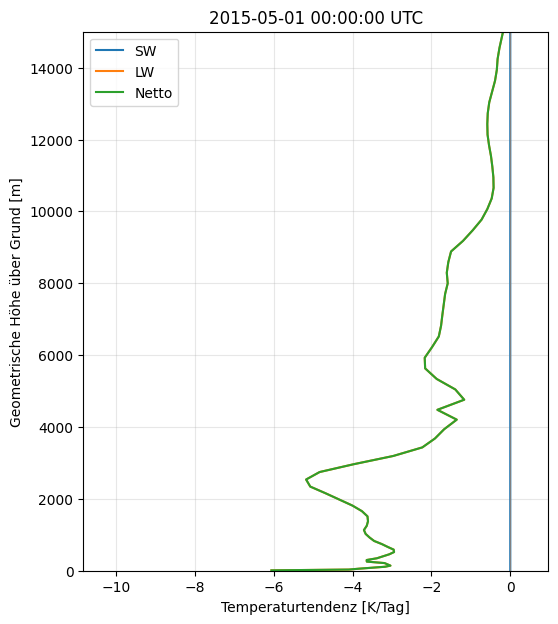

In [6]:
iy = int(np.argmin(abs(S.latitude.values - 28.6)))
ix = int(np.argmin(abs(S.longitude.values - 77.2)))

def read_rad(time):
    ds = on_fp_grid(rad.sel(valid_time=np.datetime64(time)))
    return [ds[name].transpose('model_level', 'latitude', 'longitude').values
            for name in ('avg_ttswr', 'avg_ttlwr')]

sw_test, lw_test = read_rad(TEST_TIME)
fig, ax = plt.subplots(figsize=(6, 7))
for values, label in ((sw_test, 'SW'), (lw_test, 'LW'),
                      (sw_test + lw_test, 'Netto')):
    ax.plot(values[:, iy, ix] * 86400, z_test[:, iy, ix], label=label)
ax.axvline(0, color='gray', lw=0.8)
ax.set(ylim=(0, 15000), xlabel='Temperaturtendenz [K/Tag]',
       ylabel='Geometrische Höhe über Grund [m]', title=str(TEST_TIME) + ' UTC')
ax.legend()
ax.grid(alpha=0.3)
plt.show()


## 7. Schichtmittel der volumetrischen Strahlungsquelle
Zuerst Q = Dichte × cp × Temperaturtendenz bilden (J/m³/s).
Dann die Überlappungsdicken jeder ERA5-Schicht mit jeder FLEXPART-Schicht berechnen.
Q wird innerhalb einer ERA5-Schicht als konstant angenommen und nach Dicke gemittelt.
Die Gewichte müssen jede FLEXPART-Schicht vollständig abdecken.


In [21]:
def layer_mean(source, edges, upper_bounds):
    result = []
    bottom = 0.0
    for top in upper_bounds:
        overlap = np.maximum(
            0.0, np.minimum(edges[:-1], top) - np.maximum(edges[1:], bottom)
        )
        np.testing.assert_allclose(overlap.sum(axis=0), top - bottom,
                                   rtol=1e-8, atol=1e-6)
        relevant = overlap > 0
        assert np.all(np.isfinite(source[relevant])), 'Ungültige Quellwerte'
        terms = np.zeros_like(overlap)
        np.multiply(source, overlap, out=terms, where=relevant)
        result.append(terms.sum(axis=0) / (top - bottom))
        bottom = top
    return np.stack(result)

Qsw_test = layer_mean(CP * rho_test * sw_test, edges_test, S.height.values)
Qlw_test = layer_mean(CP * rho_test * lw_test, edges_test, S.height.values)

display(pd.DataFrame({
    'Schichtobergrenze_m': S.height.values,
    'Q_SW_J_m3_s': Qsw_test[:, iy, ix],
    'Q_LW_J_m3_s': Qlw_test[:, iy, ix],
}))


,Schichtobergrenze_m,Q_SW_J_m3_s,Q_LW_J_m3_s
0,100.0,-2.846526e-07,-0.056203
1,500.0,3.245365e-06,-0.041988
2,1000.0,3.781908e-07,-0.040140
3,2000.0,-1.053316e-06,-0.043321
4,3000.0,5.999513e-07,-0.049683
5,5000.0,2.307891e-07,-0.017529
6,50000.0,1.338277e-07,-0.001571


## 8. Kontrollen der Mittelungsfunktion
Ein konstantes Quellfeld muss in jeder Zielschicht konstant bleiben.
Ein Feld aus Einsen ist ein mathematischer Test, keine angenommene Strahlung.


In [22]:
ones = np.ones_like(rho_test)
np.testing.assert_allclose(
    layer_mean(ones, edges_test, S.height.values), 1.0
)
print('Überlappungen vollständig; konstantes Feld bleibt konstant.')


Überlappungen vollständig; konstantes Feld bleibt konstant.


## 9. Zeitintervalle zuordnen
Hier muss `FP_LABEL_POSITION` aus Abschnitt 2 bestätigt sein.
Die Zuordnung berücksichtigt bei mittigen Intervallen zwei angrenzende ERA5-Stunden.
Meteorologie am Ende jeder ERA5-Stunde ist eine zeitliche Näherung für deren Intervall.
Die zeitliche Kovarianz zwischen Sensitivität und Quelle innerhalb einer Stunde bleibt unaufgelöst.

S hat Sekunden bereits in seiner Einheit. Bei der Faltung deshalb NICHT nochmals
mit 3600 oder dem Zellvolumen multiplizieren und S nicht auf Summe 1 normieren.


In [23]:
def radiation_hours(label):
    if FP_LABEL_POSITION not in ('start', 'center', 'end'):
        raise ValueError('Zuerst die FLEXPART-Zeitkonvention prüfen und in Zelle 2 setzen.')
    label = pd.Timestamp(label)
    hour = pd.Timedelta(hours=1)
    offset = {'start': 0.0, 'center': 0.5, 'end': 1.0}[FP_LABEL_POSITION]
    start = label - offset * hour
    end = start + hour
    for rad_end in pd.date_range(start.floor('h') + hour, end.ceil('h'), freq='h'):
        seconds = (min(end, rad_end) - max(start, rad_end - hour)).total_seconds()
        if seconds > 0:
            yield rad_end, seconds / 3600.0

def hour_source(rad_end):
    met_hour = read_met(rad_end)
    _, edges, rho = geometry(met_hour, a_half, b_half)
    sw, lw = read_rad(rad_end)
    bounds = S.height.values
    return (
        layer_mean(CP * rho * sw, edges, bounds),
        layer_mean(CP * rho * lw, edges, bounds),
    )


## 10. Vollständige Rechnung und Wiederanlauf
Erst einen Zeitstempel testen. Danach `times_to_run = S.time.values` verwenden.
Jede fertige Stunde wird atomar als eigene Datei gespeichert. Ein neuer Start überspringt sie.
Eine Konfigurationskennung trennt Zeitkonventionen und verhindert die Wiederverwendung
unter einer anderen Einstellung. Bei einer Änderung der Methodik neuen Ergebnisordner verwenden.
Der Rechenlauf darf dauern: auf einem Compute-Node mit ausreichend RAM ausführen.


In [27]:
def run_budget(times):
    if FP_LABEL_POSITION not in ('start', 'center', 'end'):
        raise ValueError('FLEXPART-Zeitkonvention noch nicht bestätigt.')
    config = dict(method='v1-geometric-layer-mean',
                  fp=str(FP_FILE), fp_size=FP_FILE.stat().st_size,
                  fp_mtime=FP_FILE.stat().st_mtime_ns,
                  radiation=[(str(p), p.stat().st_size, p.stat().st_mtime_ns)
                             for p in rad_files],
                  label_position=FP_LABEL_POSITION, cp=CP,
                  heights=S.height.values.tolist())
    digest = hashlib.sha256(json.dumps(config, sort_keys=True).encode()).hexdigest()[:12]
    folder = RESULT_DIR / digest
    folder.mkdir(parents=True, exist_ok=True)
    (folder / 'configuration.json').write_text(json.dumps(config, indent=2))
    paths = []
    cached_time, cached_source = None, None

    for label in times:
        stamp = pd.Timestamp(label)
        target = folder / stamp.strftime('radiation_%Y%m%d%H.nc')
        paths.append(target)
        if target.exists():
            print('Vorhanden:', stamp, flush=True)
            continue
        qsw = np.zeros((S.sizes['height'], S.sizes['latitude'], S.sizes['longitude']))
        qlw = np.zeros_like(qsw)
        for rad_end, fraction in radiation_hours(stamp):
            if cached_time != rad_end:
                cached_source = hour_source(rad_end)
                cached_time = rad_end
            qsw += fraction * cached_source[0]
            qlw += fraction * cached_source[1]
        sensitivity = S.sel(time=label).values.astype('float64')
        assert np.all(np.isfinite(sensitivity))
        assert np.all(sensitivity >= 0)
        coords = {d: S[d] for d in ('height', 'latitude', 'longitude')}
        ds = xr.Dataset({
            'dh_sw': xr.DataArray(sensitivity * qsw,
                                 dims=tuple(coords), coords=coords),
            'dh_lw': xr.DataArray(sensitivity * qlw,
                                 dims=tuple(coords), coords=coords),
        }).expand_dims(time=[label])
        ds['dh_net'] = ds.dh_sw + ds.dh_lw
        for variable in ds.data_vars:
            ds[variable].attrs['units'] = 'J kg-1'
        ds.attrs.update(config_id=digest, time_label_position=FP_LABEL_POSITION,
                        method='Layer-uniform volumetric radiation source; approximate')
        temporary = target.with_suffix('.nc.part')
        ds.to_netcdf(temporary, engine='netcdf4', encoding={
            v: {'zlib': True, 'complevel': 4} for v in ds.data_vars
        })
        temporary.replace(target)
        print('Gespeichert:', stamp,
              'Netto:', float(ds.dh_net.sum(skipna=False)), 'J/kg', flush=True)
    return paths

# Zuerst genau eine FLEXPART-Stunde testen:
times_to_run = S.time.values
# Danach für den ganzen Zeitraum ersetzen durch:
# times_to_run = S.time.values
result_paths = run_budget(times_to_run)


Vorhanden: 2015-05-01 00:00:00
Gespeichert: 2015-05-01 01:00:00 Netto: -45.66123541052539 J/kg
Gespeichert: 2015-05-01 02:00:00 Netto: -32.87497834612803 J/kg
Gespeichert: 2015-05-01 03:00:00 Netto: -14.423095828562857 J/kg
Gespeichert: 2015-05-01 04:00:00 Netto: 2.1042000882365848 J/kg
Gespeichert: 2015-05-01 05:00:00 Netto: 15.392779724431753 J/kg
Gespeichert: 2015-05-01 06:00:00 Netto: 25.313671279901218 J/kg
Gespeichert: 2015-05-01 07:00:00 Netto: 31.379778044570024 J/kg
Gespeichert: 2015-05-01 08:00:00 Netto: 33.112453336374244 J/kg
Gespeichert: 2015-05-01 09:00:00 Netto: 31.89687348149246 J/kg
Gespeichert: 2015-05-01 10:00:00 Netto: 26.884206878986028 J/kg
Gespeichert: 2015-05-01 11:00:00 Netto: 17.229905524957296 J/kg
Gespeichert: 2015-05-01 12:00:00 Netto: 3.831108718062393 J/kg
Gespeichert: 2015-05-01 13:00:00 Netto: -14.90849588923141 J/kg
Gespeichert: 2015-05-01 14:00:00 Netto: -33.43898324517807 J/kg
Gespeichert: 2015-05-01 15:00:00 Netto: -41.38516681543754 J/kg
Gespeicher

## 11. Summen und Karten
Die Werte sind Beiträge zu einer mittleren spezifischen Energie am Rezeptor,
keine gesamte Energiemenge in Joule. Der vollständige Strahlungsbeitrag erfordert
alle FLEXPART-Stunden. `skipna=False` verhindert, dass fehlende Beiträge verschwinden.


Vollständiger Zeitraum: True


<xarray.Dataset> Size: 24B
Dimensions:  ()
Data variables:
    dh_sw    float64 8B 7.336e+03
    dh_lw    float64 8B -1.486e+04
    dh_net   float64 8B -7.521e+03

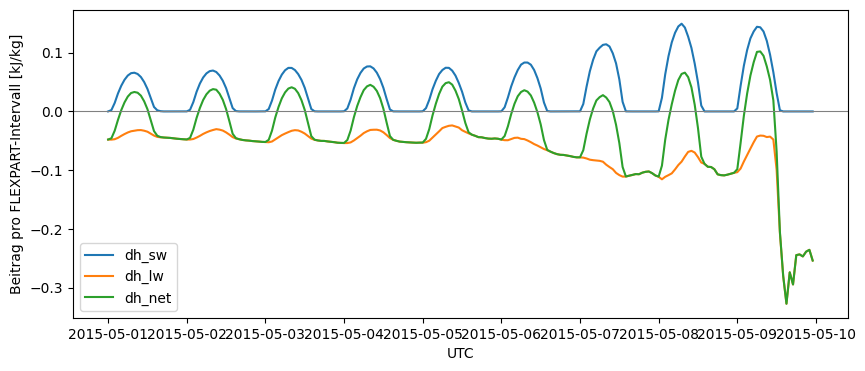

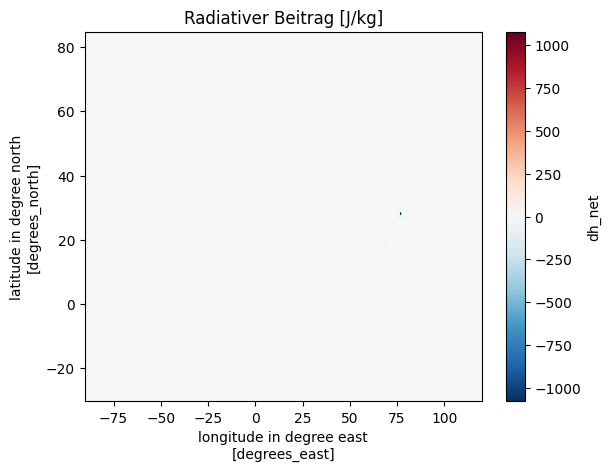

In [28]:
budget = xr.open_mfdataset(result_paths, combine='by_coords')
complete = np.array_equal(budget.time.values, S.time.values)
print('Vollständiger Zeitraum:', complete)
totals = budget.sum(dim=['time', 'height', 'latitude', 'longitude'], skipna=False).compute()
display(totals)

timeline = budget.sum(dim=['height', 'latitude', 'longitude'], skipna=False).compute()
fig, ax = plt.subplots(figsize=(10, 4))
for name in ('dh_sw', 'dh_lw', 'dh_net'):
    ax.plot(timeline.time, timeline[name] / 1000, label=name)
ax.set(ylabel='Beitrag pro FLEXPART-Intervall [kJ/kg]', xlabel='UTC')
ax.axhline(0, color='gray', lw=0.8)
ax.legend()
plt.show()

net_map = budget.dh_net.sum(dim=['time', 'height'], skipna=False).compute()
limit = float(abs(net_map).max())
if limit > 0:
    net_map.plot(x='longitude', y='latitude', cmap='RdBu_r', vmin=-limit, vmax=limit)
    plt.title('Radiativer Beitrag [J/kg]' + ('' if complete else ' – nur Testzeitraum'))
    plt.show()


## 12. Bilanz desselben Laufs ergänzen
Erst mit vollständigem Zeitraum. Oberflächenbeitrag und Partikel-MSE-Änderung müssen
aus DIESEM Neu-Delhi-Lauf stammen, mit denselben Zeitgrenzen und derselben Normierung.
Die früheren Karachi-Werte dürfen nicht eingesetzt werden.
Die verbleibende Differenz ist ein Bilanzrest, kein Beweis für einen einzelnen fehlenden Prozess.


In [30]:
surface_contribution = 8356.2  # J/kg, aus demselben Neu-Delhi-Lauf
particle_mse_change = 7957.9   # J/kg, aus demselben Neu-Delhi-Lauf

if complete and surface_contribution is not None and particle_mse_change is not None:
    radiation_contribution = float(totals.dh_net)
    predicted = surface_contribution + radiation_contribution
    residual = particle_mse_change - predicted
    print('Oberfläche:', surface_contribution, 'J/kg')
    print('Strahlung:', radiation_contribution, 'J/kg')
    print('Summe:', predicted, 'J/kg')
    print('Partikel-MSE-Änderung:', particle_mse_change, 'J/kg')
    print('Bilanzrest (Partikel minus Summe):', residual, 'J/kg')
else:
    print('Noch keine vollständige gemeinsame Bilanz: Zeitraum/Eingaben prüfen.')


Oberfläche: 8356.2 J/kg
Strahlung: -7520.757942966515 J/kg
Summe: 835.442057033486 J/kg
Partikel-MSE-Änderung: 7957.9 J/kg
Bilanzrest (Partikel minus Summe): 7122.457942966514 J/kg


## Quellen und verbleibende Prüfungen
- [ECMWF: Modellleveldruck, Geopotential und geometrische Höhe](https://confluence.ecmwf.int/pages/viewpage.action?pageId=226496386)
- [FLEXPART: Konfiguration und Mittelungsintervalle](https://flexpart.img.univie.ac.at/docs/configuration.html)
- [FLEXPART: Sensitivitäten und Einheiten](https://gmd.copernicus.org/articles/12/4955/2019/index.html)
- [ERA5: zeitliche Bedeutung der Strahlungstendenzen, Abschnitt 2.2](https://acp.copernicus.org/articles/21/8393/2021/)

**Vor einer wissenschaftlichen Interpretation:** Zeitkonvention des konkreten Builds prüfen;
konservativen AIRTRACER bestätigen; ERA5-Orographie mit FLEXPART-ORO vergleichen;
Levelkoeffizienten und Koordinaten der Strahlung mit den Metdaten abgleichen;
Sensitivität auf feinere Höhenschichten und zeitliche Meteorologiezuordnung untersuchen.
Gleiche Gitterabstände allein machen Zellmittel nicht exakt gleichwertig.

Das Notebook wurde ohne Zugriff auf die Serverdaten erstellt. Die eingebauten Struktur-
und Konsistenzprüfungen müssen in deiner Remote-Kernel-Umgebung ausgeführt werden.
